# Boosting - ADABOOST


<!-- TOC START min:2 max:4 link:true asterisk:true update:true -->
* [What you will learn in this class](#what-you-will-learn-in-this-class)
* [Introduction](#introduction)
* [AdaBoost](#adaboost)
  * [Algorithm](#algorithm)
  * [Performance Condition](#performance-condition)
  * [Overfitting AdaBoost](#overfitting-adaboost)
  * [Margins](#margins)
* [Gradient Boosting (XGBoost)](#gradient-boosting-xgboost)
<!-- TOC END -->

In [ ]:
import time

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.datasets import make_classification, make_friedman1, make_moons
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBRegressor

# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

## What you will learn in this class

Here we define boosting. Boosting improves the performance of a simple supervised Machine Learning model by repeating the learning step several times in a row, each time taking the previous prediction errors into account, and then combining the different models. This method uses the notion of "aggregating" that we saw previously.

## Introduction

Boosting algorithms aim to turn weak predictors into a strong predictor: starting from models that are only partially correlated with the true distribution of the data, they build a new model that can approach this distribution as closely as desired.

Many boosting algorithms exist, but the first major breakthrough in this field was the AdaBoost method, invented by Schapire and Freund, who won the prestigious Gödel Prize in computer science for it in 2003.

Imagine you are preparing for an extremely difficult exam. You have read through the chapters of your course once, and you test your knowledge on past exam questions. Your score on this first mock exam tells you which parts of the course you know well, and which ones need a little more work. How will you plan your second round of studying based on this first attempt? You will probably go through the content again and spend a little more time on what you had more difficulties with, and a little less time on the chapters you got right the first time. Boosting follows exactly the same logic.

The general idea of the AdaBoost method is to build models one after the other, each one a sufficiently good predictor, by changing the weights given to the observations: we increase the importance of the observations that are misclassified, and reduce the importance of those that are correctly classified. In the end, the models are aggregated, and the weight of each model depends on its training error.

## AdaBoost

### Algorithm

The simplest way to introduce the AdaBoost method is to describe its algorithm in pseudo-code. We consider a modeling problem with observations $X_1,...,X_i,...,X_n$ (vectors whose elements are the values of the explanatory variables) and a binary target variable $Y\in\{-1,+1\}$.

The algorithm is written as follows:

:::tip Intuition
Read the algorithm as a loop with three questions. **How wrong is this model?** $\epsilon_t$ is the share of the *weight* that falls on misclassified points (not the plain share of points). **How much say does it get?** $\alpha_t$ is large when $\epsilon_t$ is small: $\epsilon_t = 0.1$ gives $\alpha_t \approx 1.10$, $\epsilon_t = 0.3$ gives $\alpha_t \approx 0.42$, and a coin flip ($\epsilon_t = 0.5$) gives $\alpha_t = 0$. **Who needs more attention next time?** Since $Y_i h_t(X_i)$ is $+1$ when the prediction is right and $-1$ when it is wrong, the update multiplies the weight of a wrong point by $e^{\alpha_t}$ and the weight of a right point by $e^{-\alpha_t}$.
:::

**Initialization:**

$D_{1}(i)=\frac{1}{n}\;\text{for}\;i\in\{1,\dots,n\}$
At the start, the AdaBoost algorithm gives the same weight to all observations.


**For** $t\;\in[1,T]$ **:**

* Train a model on the training data by weighting the observations with $D_t$

* We get a predictor that we write $h_t:\;X\rightarrow\{-1,+1\}$

* We compute the weighted prediction error:

$\epsilon_t=\sum_{i=1}^{n}D_t(i)\cdot1[h_t(X_i)\neq{Y_i}]$ (the weights $D_t$ sum to 1)

* We compute:

 $\alpha_t=\frac{1}{2}ln(\frac{1-\epsilon_t}{\epsilon_t})$, the weight of this model in the final aggregation

* We update the observation weights:

$D_{t+1}(i)=\frac{D_t(i)exp(-\alpha_t{Y_i}h_t(X_i))}{Z_t}$


where $Z_t$ is simply the normalization factor such that

$\sum_{i=1}^{n}D_{t+1}(i)=1$


**Result:** the final model obtained from the AdaBoost algorithm is the following:


$H(X)=sign(\sum_{t=1}^{T}\alpha_t{h_t}(X))=sign(F(x))$


So we start by giving the same weight to all observations. Then we build prediction models one after the other (for example logistic regressions). At each iteration, we change the weights of the observations, and these weights influence how the model parameters are optimized. The weights of the observations that were badly predicted increase, and the weights of the observations that were well predicted decrease. This forces the next model to pay more attention to the observations that the previous model found hard to predict. In the end, the final model is a weighted vote of the different models, based on their individual performance on the training data. Models that performed better get more weight in the vote than models that performed worse.

**See it with data 🔬 AdaBoost step by step, by hand**

Let's run the algorithm above on 40 points in 2D, with the simplest possible weak model: a *decision stump* (a tree with a single split). We code every line of the loop ourselves, and keep the weights $D_t$ after each round.

In [ ]:
X, y01 = make_moons(n_samples=40, noise=0.25, random_state=0)
y = np.where(y01 == 1, 1, -1)                        # the classes must be -1 and +1

n = len(y)
D = np.full(n, 1 / n)                                # initialization: same weight for everyone
weights, rounds = [D], []
for t in range(1, 4):
    h = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=D).predict(X)   # weak model h_t
    eps = D[h != y].sum()                            # weighted error
    alpha = 0.5 * np.log((1 - eps) / eps)            # say of this model in the final vote
    D = D * np.exp(-alpha * y * h)                   # wrong points go up, right points go down
    D = D / D.sum()                                  # normalization (Z_t)
    weights.append(D)
    rounds.append({"round": t, "misclassified points": int((h != y).sum()), "weighted error ε": round(eps, 3),
                   "α": round(alpha, 3), "largest weight after the round": round(D.max(), 3)})
pd.DataFrame(rounds)

,round,misclassified points,weighted error ε,α,largest weight after the round
0,1,10,0.250,0.549,0.050
1,2,12,0.200,0.693,0.042
2,3,12,0.281,0.469,0.074


In [ ]:
titles = ["Start: all weights equal", "After round 1", "After round 2", "After round 3"]
fig = make_subplots(rows=1, cols=4, subplot_titles=titles, shared_yaxes=True)
for k, w in enumerate(weights):
    fig.add_trace(go.Scatter(
        x=X[:, 0], y=X[:, 1], mode="markers", showlegend=False,
        marker=dict(size=5 + 400 * w, color=np.where(y == 1, "#3B47C4", "#E4572E"), line=dict(width=1, color="white")),
        hovertext=[f"weight = {v:.3f}" for v in w]), row=1, col=k + 1)
fig.update_xaxes(title_text="x1")
fig.update_yaxes(title_text="x2", col=1)
fig.update_layout(title="AdaBoost: marker size = weight of the observation (blue = +1, orange = -1)", height=380)
fig.show()

At the start, each of the 40 points weighs $1/40 = 0.025$. The first stump misclassifies 10 points, so $\epsilon_1 = 0.25$ and $\alpha_1 = 0.549$; after the update, those 10 points share half of the total weight, and they grow on the plot. The next stumps are trained on this new weighting: they get $\epsilon_2 = 0.20$ ($\alpha_2 = 0.693$) and $\epsilon_3 = 0.281$ ($\alpha_3 = 0.469$). After 3 rounds, the heaviest point weighs 0.074, three times its starting weight: these are the points near the border between the two moons, the ones that are hard to classify.

### Performance Condition

Intuitively, a binary classification model needs three characteristics to be efficient and accurate:


* It must have been trained on a sufficient number of examples
* It must describe the observations of the training set accurately, i.e. the training error must be small.
* It must be simple (a common idea in statistics is that, in general, a simple model has a better chance of performing well on new data than a complex one; this idea is often called Ockham's razor).

These essential conditions need to be formalized mathematically to be of practical use. It is rather difficult to say in advance exactly how many observations make a training set large enough: it depends on the relative proportions of positive and negative observations, and on the type of model we want to use with the AdaBoost method. For example, we will probably need fewer observations to correctly optimize a logistic regression (this does not guarantee good results, but at least the parameters will converge), and more observations if our binary classification model is more complex, such as a neural network.

The second performance criterion, commonly called the _weak learning condition_, is the idea that each binary classification model in the final model must have a training error smaller than pure chance. Mathematically, this means that:

$\epsilon_t\;<\frac{1}{2}-\gamma$

where $\gamma\;>0$.

Note that this specific criterion assumes that the observations are equally split between the two classes. In general, this criterion can be written:

$\epsilon_t\;<\;\text{baseline error}-\gamma$, where $\gamma>0$

**See it with data 🔬 A weak learner alone vs 50 weak learners together**

A decision stump is the textbook weak learner: a single split cannot draw the curved border between two moons. Does it satisfy the weak learning condition, and what does AdaBoost make of 50 of them? We use 1,000 noisy points, with 30% kept aside as a test set.

In [ ]:
X, y = make_moons(n_samples=1000, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

stump = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train)
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=0).fit(X_train, y_train)

print(f"One stump            : test accuracy = {stump.score(X_test, y_test):.3f}")
print(f"AdaBoost of 50 stumps: test accuracy = {ada.score(X_test, y_test):.3f}")
errors = ada.estimator_errors_                       # weighted error ε_t of each stump, on its own weighting
print(f"Weighted error of the 50 stumps: from {errors.min():.3f} to {errors.max():.3f}")

One stump            : test accuracy = 0.773
AdaBoost of 50 stumps: test accuracy = 0.890
Weighted error of the 50 stumps: from 0.181 to 0.485


In [ ]:
fig = go.Figure(go.Scatter(x=np.arange(1, len(errors) + 1), y=errors, mode="lines+markers", name="ε_t"))
fig.add_hline(y=0.5, line_dash="dash", annotation_text="0.5: no better than chance")
fig.update_layout(title="Weighted error of each stump during boosting", xaxis_title="round t",
                  yaxis_title="weighted error ε_t", yaxis_range=[0, 0.55])
fig.show()

A single stump reaches 0.773 test accuracy; 50 stumps combined by AdaBoost reach 0.890. Every stump respects the weak learning condition: their weighted errors go from 0.181 to 0.485, always below 0.5. Notice how the error climbs towards 0.5 over the rounds: the easy points are already handled, so each new stump faces the hard points, which carry most of the weight. Its $\gamma$ gets small, and so does its say $\alpha_t$ in the vote.

### Overfitting AdaBoost

Once these two conditions are met, the AdaBoost algorithm brings the training error down to a minimal level in relatively few iterations. However, as is often the case in statistics, a minimal training error often means overfitting: the model sticks too closely to the training data. The figure below shows how the errors evolve as boosting rounds are added:


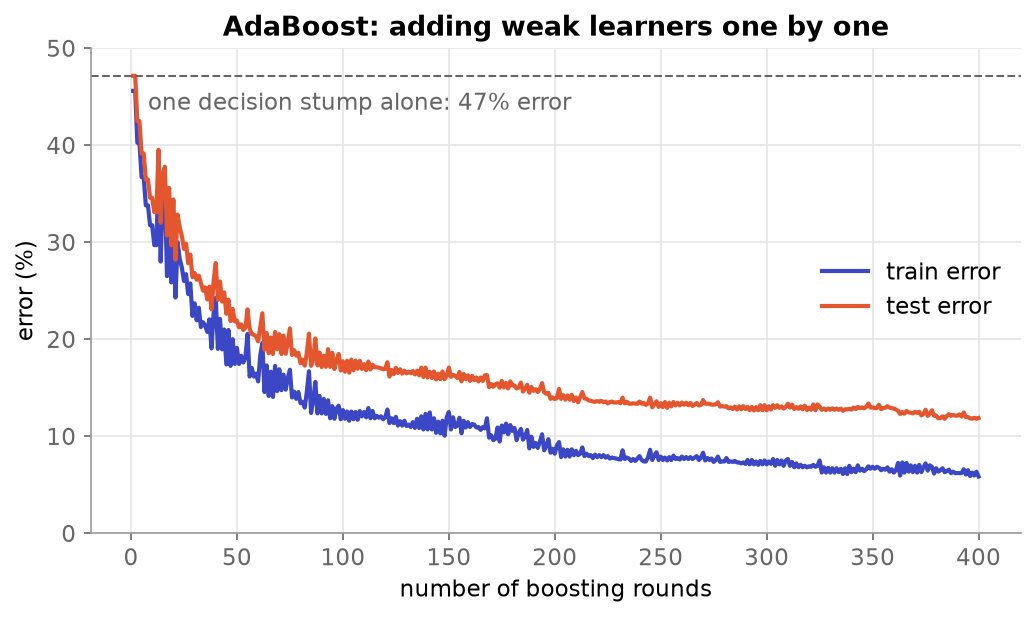


Both errors drop quickly at first, then the training error keeps decreasing faster than the test error, and a gap opens between them. If too many iterations are performed, the test error can stop improving, or even increase again: the model is overfitting.

:::tip Intuition
Why can boosting overfit? Round after round, AdaBoost gives more and more weight to the points it keeps getting wrong. If some of those points are just noise (a mislabelled observation, an outlier), the later models bend over backwards to fit them, like a student who memorizes the odd typo in a past exam instead of learning the course.
:::




### Margins

We have seen above that the AdaBoost algorithm sometimes produces an overfitted model, i.e. a model that performs very well, or even perfectly, on the training data, but gives sub-optimal results on the validation data. However, it does not always fall into that trap. There are cases where the final model predicts the validation data better and better as the number of iterations increases. There is even a theoretical framework in which AdaBoost gives a model whose error on the validation sample reaches an optimal level!

To explain this theoretical framework, we introduce the notion of margin. Our model aggregates weak learners, and its predictions come from a weighted vote. Depending on the result of the vote, we will not necessarily have the same confidence in the prediction for every observation. Just as in a real-world election, we are more likely to trust a decision that wins a large majority of the votes than one that wins a small majority. Behind this idea of a strong or weak majority is the notion of margin. The margin of an observation is a value between -1 and 1, defined as follows:


$\text{margin}(X_i)=\dfrac{\sum_{t:\,h_t(X_i)=Y_i}\alpha_t\;-\;\sum_{t:\,h_t(X_i)\neq Y_i}\alpha_t}{\sum_{t}\alpha_t}$


It is the difference between the total weight of the models that predict correctly and the total weight of the models that are wrong.

:::tip Intuition
A small example: three models with $\alpha = 0.9$, $0.6$ and $0.3$. If the first two are right on an observation and the third is wrong, its margin is $\frac{0.9 + 0.6 - 0.3}{0.9 + 0.6 + 0.3} = \frac{1.2}{1.8} \approx 0.67$: a comfortable win. If only the first one is right, the margin is $\frac{0.9 - 0.6 - 0.3}{1.8} = 0$: a tie, the prediction hangs by a thread. A margin of $+1$ means every model is right, $-1$ means every model is wrong, and a negative margin means the final vote is wrong.
:::


This concept of margin is essential. It can be shown that the model produced by AdaBoost, and more generally any model based on a majority vote of elementary models, has a generalization error (error on the validation set) that does not depend on the number of iterations (the number of elementary models in the final predictor), but only on the margins obtained for the observations of the training sample. In other words, the number of models in the final vote does not matter: the higher the margins of the training observations, the smaller the validation error. So if adding new models increases these confidence margins, we do not risk overfitting. On the contrary, the final model should perform better on the validation data.


The figure below shows this on a simulated dataset (AdaBoost with trees of depth 4, 1,000 training observations). On the left, the training error reaches zero after about 50 rounds, yet the test error keeps going down, from about 14% to 12% after 1,000 rounds. On the right, the cumulative distribution of the training margins after 5 rounds (dotted line), 100 rounds (dashes) and 1,000 rounds (full line): with more rounds, the smallest margins keep growing, and every training observation ends up with a comfortable positive margin. This is why adding rounds keeps improving the predictions on new data.

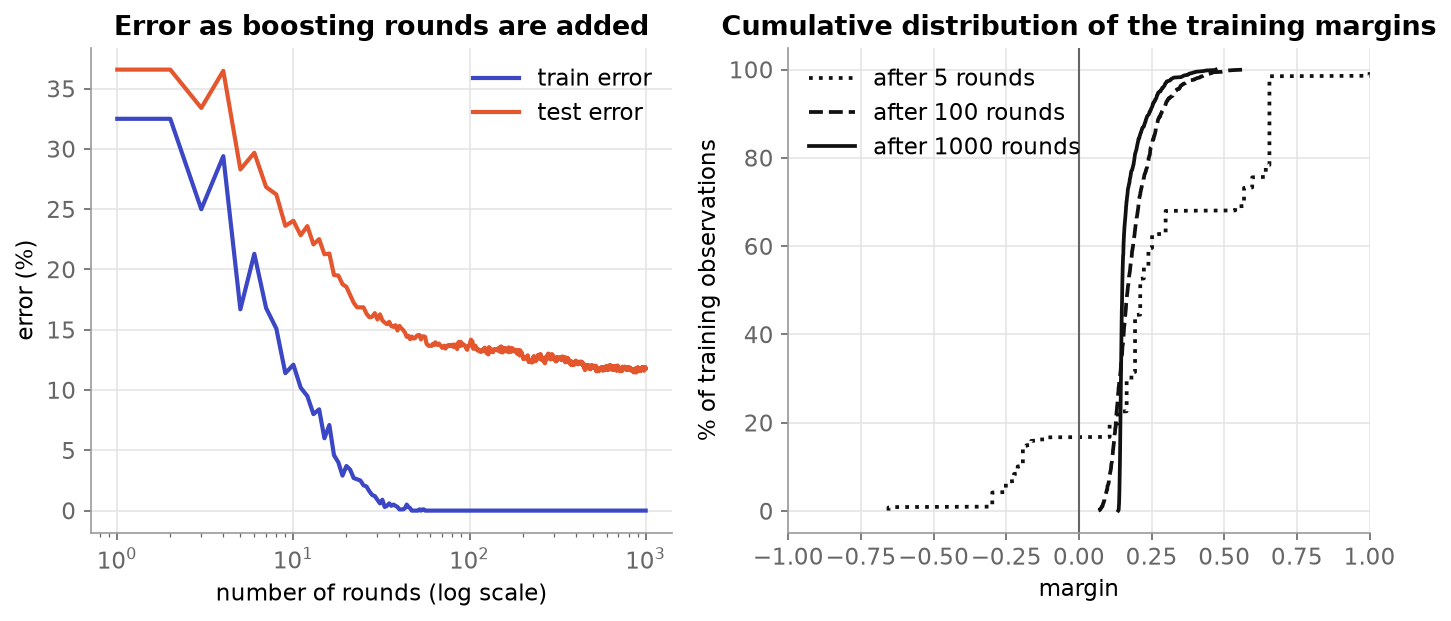

**See it with data 🔬 Margins growing after the training error hits zero**

Let's reproduce the figure above on a simulated dataset (1,000 training and 1,000 test observations, 5% of labels flipped at random, AdaBoost with trees of depth 2). From each model $h_t$ and its weight $\alpha_t$, we compute the margin of every training observation after 5, 50 and 300 rounds, exactly with the formula of the margin.

In [ ]:
X, y = make_classification(n_samples=2000, n_features=10, n_informative=5, flip_y=0.05, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=300, random_state=0).fit(X_train, y_train)

right = np.array([np.where(m.predict(X_train) == y_train, 1, -1) for m in ada.estimators_])  # +1 right, -1 wrong
alphas = ada.estimator_weights_[: len(right)]
train_err = 1 - np.array(list(ada.staged_score(X_train, y_train)))     # error after 1, 2, ..., 300 rounds
test_err = 1 - np.array(list(ada.staged_score(X_test, y_test)))
margins = {}
for T in [5, 50, 300]:
    margins[T] = (alphas[:T, None] * right[:T]).sum(axis=0) / alphas[:T].sum()
    print(f"{T:>3} rounds: train error = {train_err[T - 1]:.3f}, test error = {test_err[T - 1]:.3f}, "
          f"smallest margin = {margins[T].min():+.3f}")

  5 rounds: train error = 0.130, test error = 0.111, smallest margin = -1.000
 50 rounds: train error = 0.066, test error = 0.118, smallest margin = -0.178
300 rounds: train error = 0.000, test error = 0.104, smallest margin = +0.003


In [ ]:
fig = go.Figure()
for T, m in margins.items():
    fig.add_trace(go.Scatter(x=np.sort(m), y=np.arange(1, len(m) + 1) / len(m), mode="lines", name=f"{T} rounds"))
fig.update_layout(title="Cumulative distribution of the training margins",
                  xaxis_title="margin", yaxis_title="share of training observations with a smaller margin")
fig.show()

After 5 rounds, some training points still have a margin of $-1.000$ (every model is wrong on them) and the training error is 0.130. After 50 rounds the smallest margin is $-0.178$, and after 300 rounds the training error is 0 and every margin is positive (the smallest is $+0.003$). The test error does not go up while this happens: 0.111 after 5 rounds, 0.118 after 50, 0.104 after 300. On the plot, the curves move to the right on their left end: the worst-classified points get pushed towards safer margins. Here the gain is modest, because the 5% of flipped labels are points that no model can (or should) get right.

## Gradient Boosting (XGBoost)

Another very popular boosting algorithm is gradient boosting, which works a little differently from AdaBoost. Let $X$ be our training data and $y$ the target variable. Gradient boosting trains a sequence of models, written $F_1, ..., F_m$, whose goal is to predict $y$ as accurately as possible.


:::tip Intuition
Think of a golfer. The first shot ($F_1$) lands somewhere near the hole. The second shot does not start again from the tee: it starts from where the ball is and only tries to cover the remaining distance (the residual). Each new shot is shorter and more precise. AdaBoost *re-weights* the observations it gets wrong; gradient boosting directly trains the next model on *what is still missing*.
:::

The algorithm starts by predicting $y$ with $F_1$, which gives:
$\hat{F_1}(X) = \hat{y}_1$ where $\hat{F_1}$ is the trained version of model $F_1$
This model isn't necessarily very accurate at this point, so we may want to add another model to predict $y$ better. Let's call this new predictor $f_1$. The idea is to solve:
$F_2(X) = \hat{F_1}(X) + f_1(X) = y$
$f_1(X) = y - \hat{F_1}(X) = y - \hat{y}_1 = \epsilon_1$
So the idea is to train the new predictor $f_1$ to predict the residuals $\epsilon_1$ of the first model, and not $y$ directly.
The sequence of models is built iteratively with the following equation:
$F_{i+1} = \hat{F_{i}} + f_i$ 
where $f_i$ is trained on the residuals of $F_i$, written $\epsilon_i$.

**See it with data 🔬 Gradient boosting by hand, step by step**

Let's build $F_1, F_2, F_3, F_4$ ourselves on 80 points of a noisy wavy curve. $F_1$ is the simplest possible model, the mean of $y$. Each next step trains a small regression tree (depth 2) on the residuals of the current model and adds it. As real implementations do, we add each tree multiplied by a **learning rate** (here 0.5), so that every step corrects only part of the error (more on this just below).

In [ ]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 10, 80))
y = 3 * np.sin(x) + x / 2 + rng.normal(0, 0.5, 80)
X = x.reshape(-1, 1)

learning_rate = 0.5
pred = np.full_like(y, y.mean())                         # F_1: predict the mean for everyone
steps = [pred.copy()]
for i in range(3):
    residuals = y - pred                                 # what is still missing
    f = DecisionTreeRegressor(max_depth=2).fit(X, residuals)   # f_i is trained on the residuals
    pred = pred + learning_rate * f.predict(X)           # F_(i+1) = F_i + learning_rate * f_i
    steps.append(pred.copy())
for k, p in enumerate(steps):
    print(f"F_{k + 1}: mean absolute residual = {np.abs(y - p).mean():.3f}")

F_1: mean absolute residual = 1.972
F_2: mean absolute residual = 1.295
F_3: mean absolute residual = 0.917
F_4: mean absolute residual = 0.740


In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Prediction after each step", "Residuals after each step"])
fig.add_trace(go.Scatter(x=x, y=y, mode="markers", name="data", marker=dict(color="#999999")), row=1, col=1)
colors = ["#E4572E", "#F2C14E", "#4BA3C3", "#3B47C4"]
for k, p in enumerate(steps):
    fig.add_trace(go.Scatter(x=x, y=p, mode="lines", name=f"F_{k + 1}", line=dict(shape="hv", color=colors[k])), row=1, col=1)
    fig.add_trace(go.Box(y=y - p, name=f"F_{k + 1}", marker_color=colors[k], showlegend=False), row=1, col=2)
fig.update_xaxes(title_text="x", row=1, col=1)
fig.update_yaxes(title_text="y", row=1, col=1)
fig.update_yaxes(title_text="residual y - F(x)", row=1, col=2)
fig.update_layout(title="Gradient boosting: each tree corrects part of what is still missing", height=420)
fig.show()

In [ ]:
gb = GradientBoostingRegressor(n_estimators=3, learning_rate=0.5, max_depth=2).fit(X, y)
print("Same predictions as scikit-learn's GradientBoostingRegressor:", np.allclose(gb.predict(X), pred))

Same predictions as scikit-learn's GradientBoostingRegressor: True


The mean alone ($F_1$) is off by 1.972 on average. Each tree on the residuals brings this down: 1.295, then 0.917, then 0.740 after three trees. On the left, the flat line becomes a staircase that follows the wave more and more closely; on the right, the boxes of residuals shrink around 0. And scikit-learn's `GradientBoostingRegressor` with the same settings gives exactly the same predictions (`True`): this little loop *is* gradient boosting.

In practice, each new model is added with a small factor $\nu$ (between 0 and 1) called the **learning rate**: $F_{i+1} = \hat{F_i} + \nu f_i$. With a small learning rate, each tree only corrects a small part of the residuals, so we need more trees; in exchange, the model takes many small careful steps instead of a few big ones, which usually generalizes better.

**See it with data 🔬 Learning rate vs number of trees**

On a simulated regression problem (`make_friedman1`: 2,000 observations, 10 features, 5 of them useful, plus noise), we train gradient boosting with 4 learning rates and up to 300 trees of depth 3, and measure the test $R^2$ after each tree with `staged_predict`.

In [ ]:
X, y = make_friedman1(n_samples=2000, noise=1.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

curves = {}
for lr in [1.0, 0.3, 0.1, 0.03]:
    gb = GradientBoostingRegressor(learning_rate=lr, n_estimators=300, max_depth=3, random_state=0)
    gb.fit(X_train, y_train)
    curves[lr] = [r2_score(y_test, p) for p in gb.staged_predict(X_test)]   # test R² after 1, 2, ..., 300 trees

table = pd.DataFrame({f"{n} trees": {lr: c[n - 1] for lr, c in curves.items()} for n in [10, 30, 100, 300]})
table.rename_axis("learning rate").round(3)

,10 trees,30 trees,100 trees,300 trees
learning rate,,,,
1.00,0.831,0.849,0.823,0.813
0.30,0.814,0.909,0.918,0.918
0.10,0.578,0.815,0.917,0.929
0.03,0.274,0.543,0.814,0.914


In [ ]:
fig = go.Figure()
for lr, c in curves.items():
    fig.add_trace(go.Scatter(x=np.arange(1, len(c) + 1), y=c, mode="lines", name=f"learning rate = {lr}"))
fig.update_layout(title="Gradient boosting: test R² as trees are added", xaxis_title="number of trees",
                  yaxis_title="test R²", yaxis_range=[0, 1])
fig.show()

With a learning rate of 1, the model is fast (0.831 after 10 trees) but it peaks early and then gets worse (0.813 after 300 trees): it overfits. With 0.03, it is very slow (0.274 after 10 trees, 0.814 after 100) and only gets good at the end (0.914). The best score of the table, 0.929, is reached by 0.1 with 300 trees. The rule of thumb: **the smaller the learning rate, the more trees you need**, and these two hyperparameters must be tuned together.

**See it with data 🔬 XGBoost vs scikit-learn's gradient boosting**

XGBoost ("eXtreme Gradient Boosting") is a library that implements the same idea, with extra regularization of the trees and a very optimized, parallel implementation. Let's train both with the same settings (300 trees of depth 3, learning rate 0.1) on the same data.

In [ ]:
models = {"scikit-learn GradientBoosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0),
          "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0, n_jobs=2)}  # 2 CPU cores
XGBRegressor(n_estimators=1).fit(X_train[:50], y_train[:50])   # warm-up: the very first call loads the library

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    duration = time.perf_counter() - start
    print(f"{name:<30} test R² = {model.score(X_test, y_test):.3f}   fit time = {duration:.2f} s")

scikit-learn GradientBoosting  test R² = 0.929   fit time = 2.00 s


XGBoost                        test R² = 0.937   fit time = 0.20 s


Both models reach a similar score (test $R^2$ = 0.929 for scikit-learn, 0.937 for XGBoost), but XGBoost trains several times faster (compare the two training times printed above; the exact values depend on your computer). On a dataset of millions of rows, this difference is what makes XGBoost (and its cousins LightGBM, CatBoost, or scikit-learn's own `HistGradientBoostingRegressor`) the usual choice.